<a href="https://colab.research.google.com/github/Tdanso/new-google-colab-/blob/main/Work_with_Python_and_SQL_in_Google_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Step** 1: Load

In [2]:
import pandas as pd
import sqlite3
from matplotlib import pyplot as plt

df = pd.read_csv('https://raw.githubusercontent.com/jaypadhya-tt-curriculumDev/sprint4/main/titanic.csv')

#Step 2: Inspect

In [3]:
print(df.shape)
print()
df.info()
print()
print(df.head())

(891, 12)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

               

#Step 3: Clean

In [4]:
# Fill missing Age with median (quantitative — use median, not mean)
age_median = df['Age'].median()
df['Age'] = df['Age'].fillna(age_median)

# Fill missing Embarked with mode (categorical — use most frequent value)
embarked_mode = df['Embarked'].mode()[0]
df['Embarked'] = df['Embarked'].fillna(embarked_mode)

# Drop Cabin — too many missing values (77%) to be useful
df = df.drop('Cabin', axis=1)

# Check for duplicates
print(f"Duplicates: {df.duplicated().sum()}")

# Verify cleaning worked
df.info()

Duplicates: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          891 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Embarked     891 non-null    object 
dtypes: float64(2), int64(5), object(4)
memory usage: 76.7+ KB


##Step 4: Explore with Statistics and SQL
Now let's ask some business questions. We'll use both pandas and SQL to show how they complement each other:

In [5]:
# Pandas: Survival rate by gender
print(df.groupby('Sex')['Survived'].mean())
print()

# SQL: Survival rate by class and gender
conn = sqlite3.connect(':memory:')
df.to_sql('passengers', conn, index=False)

result = pd.read_sql('''
    SELECT
        Sex,
        Pclass,
        COUNT(*) AS total,
        SUM(Survived) AS survived,
        ROUND(AVG(Survived) * 100, 1) AS survival_pct
    FROM passengers
    GROUP BY Sex, Pclass
    ORDER BY survival_pct DESC
''', conn)
print(result)

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

      Sex  Pclass  total  survived  survival_pct
0  female       1     94        91          96.8
1  female       2     76        70          92.1
2  female       3    144        72          50.0
3    male       1    122        45          36.9
4    male       2    108        17          15.7
5    male       3    347        47          13.5


The SQL query produces a pivot-like breakdown in one step, the kind of output that would take several pandas operations to achieve.

#**Step** 5: Visualize

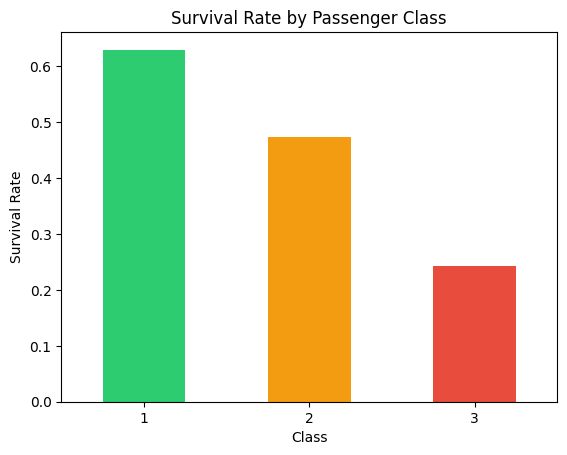

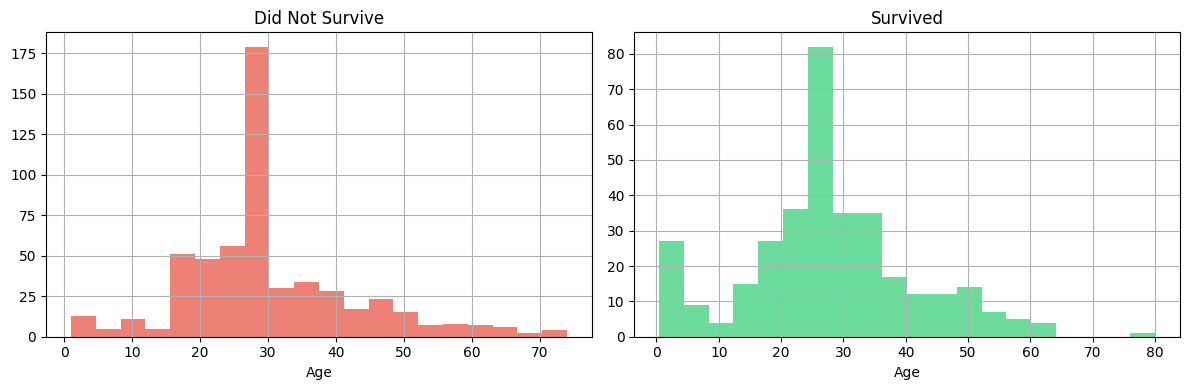

In [6]:
# Bar chart: Survival rate by class
class_survival = df.groupby('Pclass')['Survived'].mean()
class_survival.plot(kind='bar', title='Survival Rate by Passenger Class', color=['#2ecc71', '#f39c12', '#e74c3c'])
plt.ylabel('Survival Rate')
plt.xlabel('Class')
plt.xticks(rotation=0)
plt.show()

# Histogram: Age distribution of survivors vs non-survivors
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df[df['Survived'] == 0]['Age'].hist(ax=axes[0], bins=20, color='#e74c3c', alpha=0.7)
axes[0].set_title('Did Not Survive')
axes[0].set_xlabel('Age')

df[df['Survived'] == 1]['Age'].hist(ax=axes[1], bins=20, color='#2ecc71', alpha=0.7)
axes[1].set_title('Survived')
axes[1].set_xlabel('Age')

plt.tight_layout()
plt.show()

Step 6: Document and Report
Add markdown cells between each code section to document your findings. Here's an example of what that looks like:

Key Findings:

Women had a much higher survival rate (74%) than men (19%)
First-class passengers survived at 63%, while third-class survived at only 24%
Children (ages 0–10) had higher survival rates regardless of class
The "women and children first" protocol is clearly visible in the data

Practice
In your Google Colab notebook, copy the starting code into a new cell and complete the task. Compare your output to the expected result.

Task 1
Perform a mini-EDA on the Titanic dataset. In the precode, we've loaded and cleaned the data for you. Your task is to:

Create a pivot_table showing the average fare for each combination of Pclass and Sex
Print the pivot table
Hint: Use df.pivot_table(index='Pclass', columns='Sex', values='Fare', aggfunc='mean'). Assign the result to fare_pivot and print it.

In [8]:
import pandas as pd

df = pd.read_csv('https://raw.githubusercontent.com/jaypadhya-tt-curriculumDev/sprint4/main/titanic.csv')
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
df = df.drop('Cabin', axis=1)

# Create a pivot table: average Fare by Pclass and Sex
fare_pivot = df.pivot_table(index='Pclass', columns='Sex', values='Fare', aggfunc='mean')

# Print the pivot table

print(fare_pivot)

Sex         female       male
Pclass                       
1       106.125798  67.226127
2        21.970121  19.741782
3        16.118810  12.661633


Task 2
Now combine SQL and visualization. Using the cleaned dataset and the SQLite connection in the precode, write a SQL query that calculates the number of passengers and survival rate for each embarkation port. Then create a bar chart of the survival rate by port.

Hint: Query: SELECT Embarked, COUNT(*) AS total, ROUND(AVG(Survived) * 100, 1) AS survival_pct FROM passengers GROUP BY Embarked ORDER BY survival_pct DESC. Then use result.plot(x='Embarked', y='survival_pct', kind='bar').

  Embarked  total  survival_pct
0        C    168          55.4
1        Q     77          39.0
2        S    646          33.9


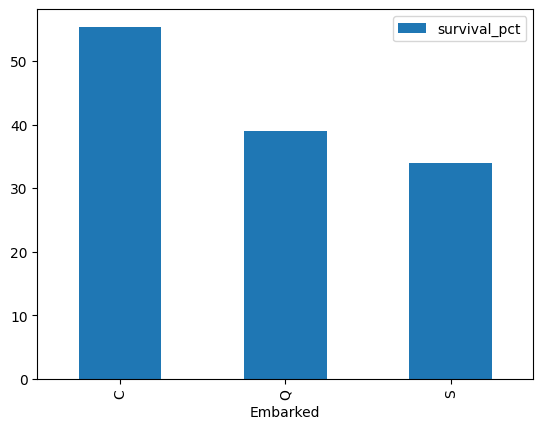

In [14]:
import pandas as pd
import sqlite3
from matplotlib import pyplot as plt

df = pd.read_csv('https://raw.githubusercontent.com/jaypadhya-tt-curriculumDev/sprint4/main/titanic.csv')
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
df = df.drop('Cabin', axis=1)

conn = sqlite3.connect(':memory:')
df.to_sql('passengers', conn, index=False)

# Write a SQL query for survival rate by Embarked port
result = '''  SELECT Embarked,
                     COUNT(*) AS total,
                     ROUND(AVG(Survived) * 100, 1) AS survival_pct
              FROM
                      passengers
              GROUP BY
                      Embarked
              ORDER BY
                      survival_pct DESC

          '''

result = pd.read_sql(result, conn)
print(result)

# Create a bar chart

result.plot(x='Embarked', y='survival_pct', kind='bar')

plt.show()